In [1]:
pip install torch torchvision numpy pandas matplotlib scikit-learn datasets pyarrow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import pandas as pd
import da

C:\Users\jai19\miniconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Load MNIST (source) and MNIST-M (target), 3-channel 32x32, 10k-image training subsample per domain
da.set_seed(0)
data = da.load_data()
da.audit(data)

mnist_train   (10000, 3, 32, 32) torch.float32 range [-1.00, 1.00] channel mean [-0.739, -0.739, -0.739] std [0.578, 0.578, 0.578]


mnist_test    (10000, 3, 32, 32) torch.float32 range [-1.00, 1.00] channel mean [-0.736, -0.736, -0.736] std [0.583, 0.583, 0.583]


mnistm_train  (10000, 3, 32, 32) torch.float32 range [-1.00, 1.00] channel mean [-0.082, -0.073, -0.18] std [0.505, 0.474, 0.517]


mnistm_test   (9001, 3, 32, 32) torch.float32 range [-1.00, 1.00] channel mean [-0.078, -0.071, -0.178] std [0.505, 0.476, 0.517]
raw 3x3 patch, MNIST ch0: [[0.6784313917160034, 0.9843137264251709, 0.9843137264251709], [0.9607843160629272, 0.9843137264251709, 0.9607843160629272], [0.5843137502670288, 0.9764705896377563, 0.9843137264251709]]
raw 3x3 patch, MNIST-M ch0: [[-0.6549019813537598, -0.6627451181411743, -0.6549019813537598], [-0.6705882549285889, -0.6549019813537598, 0.6392157077789307], [-0.6627451181411743, -0.6705882549285889, -0.6549019813537598]]


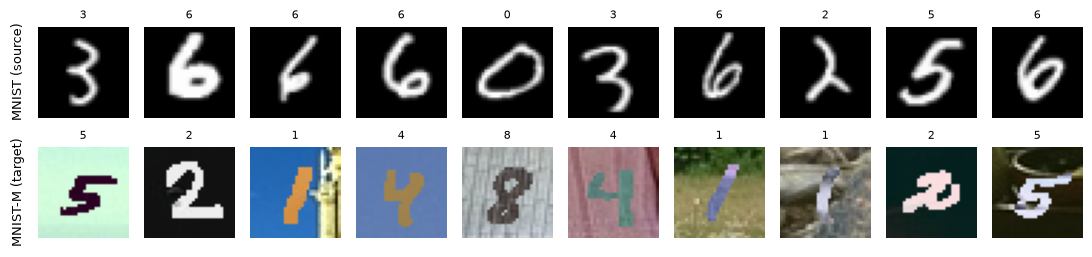

In [4]:
# Sample images from both domains
da.sample_grid(data, "figures/samples.png")

In [5]:
# Source-only, AdaBN, DANN and target-only on 3 seeds, 30 epochs each, SGD recipe of Ganin et al.
logs = []
def log(s):
    logs.append(s)
    print(s)
res, models = da.run_all(data, seeds=(0, 1, 2), epochs=30, log=log)
res["logs"] = logs

[source_only] seed 0 epoch 1/30 loss 0.5093


[source_only] seed 0 epoch 2/30 loss 0.0744


[source_only] seed 0 epoch 3/30 loss 0.0503


[source_only] seed 0 epoch 4/30 loss 0.0342


[source_only] seed 0 epoch 5/30 loss 0.0237


[source_only] seed 0 epoch 6/30 loss 0.0205


... (272 outputs left out)

seed 2 source_only: MNIST 98.67  MNIST-M 16.21


seed 2 adabn: MNIST 98.67  MNIST-M 43.96


seed 2 dann: MNIST 98.65  MNIST-M 32.40


seed 2 target_only: MNIST 91.15  MNIST-M 94.31


In [6]:
# Results table
names = {"source_only": "Source-only", "adabn": "AdaBN", "dann": "DANN", "target_only": "Target-only"}
rows = [{"Method": names[k], "MNIST acc (%)": f"{v['mnist_mean']:.2f} +/- {v['mnist_std']:.2f}",
         "MNIST-M acc (%)": f"{v['mnistm_mean']:.2f} +/- {v['mnistm_std']:.2f}",
         "% gap closed": f"{v['gap_mean']:.1f} +/- {v['gap_std']:.1f}"} for k, v in res["summary"].items()]
pd.DataFrame(rows)

,Method,MNIST acc (%),MNIST-M acc (%),% gap closed
0,Source-only,98.75 +/- 0.07,19.62 +/- 2.56,0.0 +/- 0.0
1,AdaBN,98.75 +/- 0.07,47.63 +/- 2.77,37.6 +/- 1.6
2,DANN,98.69 +/- 0.05,39.47 +/- 5.47,26.7 +/- 5.7
3,Target-only,94.01 +/- 2.02,94.18 +/- 0.10,100.0 +/- 0.0


In [7]:
# Save every number the report uses
with open("results.json", "w") as f:
    json.dump(res, f, indent=2)

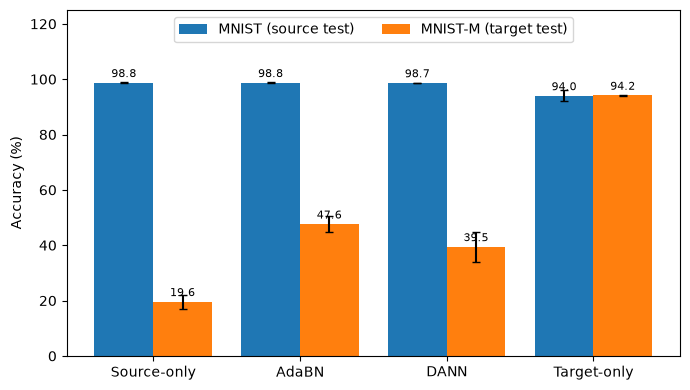

In [8]:
# Bar chart of the results table
da.bar_chart(res["summary"], "figures/results_bar.png")

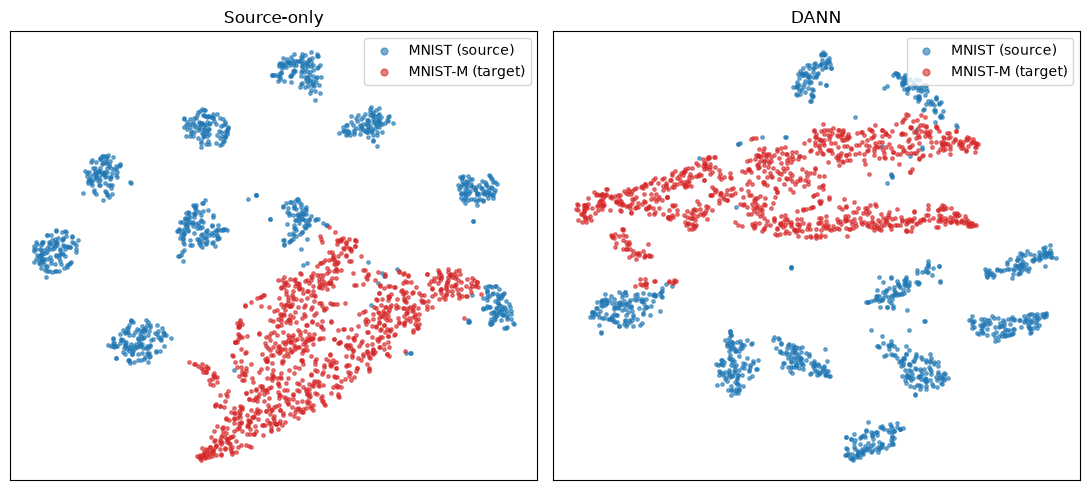

In [9]:
# t-SNE of penultimate features, source-only vs DANN (seed 0 models)
da.tsne_plot({"Source-only": models["source_only"], "DANN": models["dann"]}, data, "figures/tsne.png")

In [10]:
# Render the seed-0 training logs as images
s0 = [l for l in logs if "seed 0" in l]
da.log_image([l for l in s0 if l.startswith("[source_only]")] + [l for l in s0 if l.startswith("[target_only]")], "figures/log_supervised.png", "Source-only and target-only training (seed 0)")
da.log_image([l for l in s0 if l.startswith("[dann]")], "figures/log_dann.png", "DANN training (seed 0)")
da.log_image([l for l in logs if l.startswith("seed ")], "figures/log_eval.png", "Test accuracy per seed")